# 2. Catastrophic cancellation

**The lie.** *"Subtracting two close numbers is a harmless operation."*

When you subtract nearly equal quantities, the leading digits cancel and what
survives is pure rounding noise, magnified. The cure is almost always an
**algebraic reformulation** that avoids the subtraction.

## The setup

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams["figure.dpi"] = 110
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

In [2]:
from decimal import Decimal, getcontext
getcontext().prec = 60

def quad_naive(a, b, c):
    disc = np.sqrt(b * b - 4 * a * c)
    return (-b + disc) / (2 * a), (-b - disc) / (2 * a)

def quad_stable(a, b, c):
    disc = np.sqrt(b * b - 4 * a * c)
    q = -0.5 * (b + np.copysign(disc, b))
    return c / q, q / a

def quad_exact(a, b, c):
    a, b, c = Decimal(a), Decimal(b), Decimal(c)
    disc = (b * b - 4 * a * c).sqrt()
    return float((-b + disc) / (2 * a)), float((-b - disc) / (2 * a))

## The reality

In [3]:
a, b, c = 1.0, 1e8, 1.0
naive = quad_naive(a, b, c)
stable = quad_stable(a, b, c)
exact = quad_exact(a, b, c)
print("root next to zero:  naive =", repr(naive[0]))
print("                    stable=", repr(stable[0]))
print("                    exact =", repr(exact[0]))
print("relative error naive :", abs(naive[0] - exact[0]) / abs(exact[0]))
print("relative error stable:", abs(stable[0] - exact[0]) / abs(exact[0]))

root next to zero:  naive = np.float64(-7.450580596923828e-09)
                    stable= np.float64(-1e-08)
                    exact = -1e-08
relative error naive : 0.2549419403076172
relative error stable: 0.0


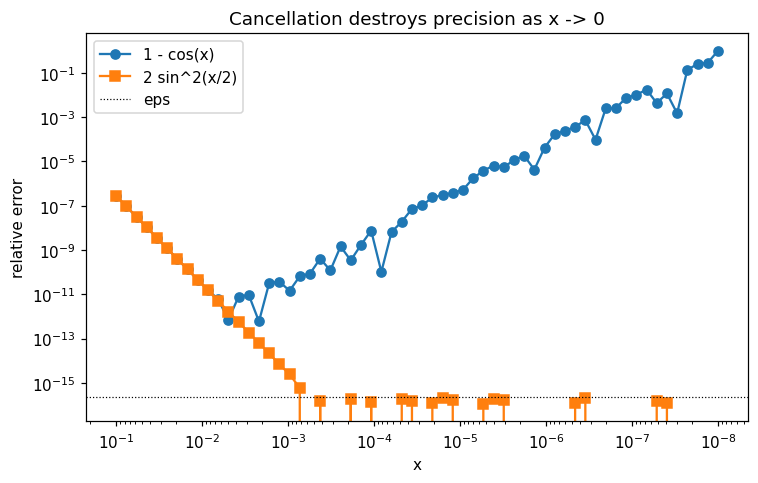

In [4]:
# 1 - cos(x) for small x: subtracts two numbers that both approach 1.
xs = np.logspace(-1, -8, 60)
naive = 1.0 - np.cos(xs)
stable = 2.0 * np.sin(xs / 2.0) ** 2
# high-precision reference from the series 1 - cos x = x^2/2 - x^4/24 + ...
truth = xs**2 / 2 - xs**4 / 24

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(xs, np.abs(naive - truth) / truth, "o-", label="1 - cos(x)")
ax.loglog(xs, np.abs(stable - truth) / truth, "s-", label="2 sin^2(x/2)")
ax.axhline(np.finfo(float).eps, color="k", ls=":", lw=0.8, label="eps")
ax.set_xlabel("x")
ax.set_ylabel("relative error")
ax.set_title("Cancellation destroys precision as x -> 0")
ax.invert_xaxis()
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "02_cancellation.png", bbox_inches="tight")
plt.show()

## The rule

- Identify subtractions of near-equal values; they are the danger.
- Reformulate:
  - quadratic formula → the stable `q = -½(b + sign(b)√disc)` form;
  - `1 − cos x` → `2 sin²(x/2)`;
  - `log(1+x)` → `math.log1p(x)`; `exp(x) − 1` → `math.expm1(x)`;
  - `√(x²+y²)` → `math.hypot(x, y)`.
- The standard library already ships the stable forms — **use them.**

```python
math.log1p(x)   # not log(1 + x)
math.expm1(x)   # not exp(x) - 1
math.hypot(x, y)# not sqrt(x*x + y*y)
```

## Taking it further

- Goldberg §1.4 (Cancellation) and the quadratic-formula example.
- Higham, ch. 1 (cancellation as loss of leading digits).
- `numpy`/`scipy.special` use the stable forms internally — e.g. `np.log1p`.